# Axial buckling of stringer-stiffened cylinders

Card and Jones [1] tested in axial compression aluminium cylinders with
external or internal longitudinal stiffeners, and compared the buckling
loads with a theory of eccentrically stiffened cylinders with the
stiffeners averaged ("smeared") over the skin, a membrane pre-buckling
state, and clamped or simply supported ends. Here two of their cylinders
with integral rectangular stringers are modelled with discrete stringers,
as in [Natural frequencies of stringer-stiffened
cylinders](stiffened_cylinder_frequencies.ipynb):

- the skin with the BFSC cylinder element of Sanders-type kinematics,
  `BFSCCylinderSanders`;
- each stringer with the BFSC plate element `BFSCPlate2D` of
  [bfscplate2d](https://github.com/saullocastro/bfscplate2d), in the
  plane $(x, r)$ of the stringer, connected to the skin as described in
  that tutorial.

The linear buckling problems $(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G)\boldsymbol{\phi} = \boldsymbol{0}$,
see [Analyses](../analyses.rst), are solved with `structsolve.lb`. The
model is given by the module `stiffened_cylinder.py`, next to this
notebook, see [Tutorials](../tutorials.rst).

## Cylinders, geometry and material

Table I of [1] gives four cylinders with integral stiffeners, machined from
aluminium plates, two 38.00 in long (cylinders 1 and 2) and two 23.75 in
long (cylinders 3 and 4), each pair with external and internal stiffeners.
Cylinders 3 and 4, the shorter ones, are modelled here: their models need
fewer elements along the axis and are solved within about a minute each.
The values below, in inches and pounds-force, are those of Table I for
$t$, $L$ and $R$, the radius of the middle surface, and of its footnote for
$E$ and $\mu$, and those of Figure 2(b) of [1] for the stiffeners:
0.097 in wide, at a spacing of 1.00 in, 0.33 in from the surface of the
skin opposite to the stiffeners to their tip, as drawn in Figure 2(b), with
fillets of radius 0.03 in, which are not modelled. The spacing gives 60
stiffeners, $2 \pi \, 9.55/1.00 = 60.0$. The plate of a stringer goes from
the middle surface of the skin to the tip, of height $H_s = 0.33 - t/2$.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import spsolve
from structsolve import lb

from stiffened_cylinder import StiffenedCylinder, wave_numbers, W

# Table I of Card and Jones (1966), with the values of N in lb/in
cylinders = {
    3: dict(side='external', t=0.0275, L=23.75, R=9.55, At=3.70,
            Pe=127.2e3, ne=7, Ne=2120., Nc=2595., Ns=1326.),
    4: dict(side='internal', t=0.0280, L=23.75, R=9.55, At=3.63,
            Pe=58.0e3, ne=6, Ne=965., Nc=1226., Ns=722.),
}
E = 10.5e6  # psi
mu = 0.32
nstringers = 60
bs = 0.097  # in, Figure 2(b)
depth = 0.33  # in, from the skin surface opposite to the stiffeners

for k, c in cylinders.items():
    Hs = depth - c['t']/2
    area = 2*np.pi*c['R']*c['t'] + nstringers*bs*Hs
    print('cylinder %d: H_s = %.4f in, modelled area %.2f in^2, '
          'A_t of Table I %.2f in^2, P_e/(2 pi R) = %.0f lb/in'
          % (k, Hs, area, c['At'], c['Pe']/(2*np.pi*c['R'])))

cylinder 3: H_s = 0.3163 in, modelled area 3.49 in^2, A_t of Table I 3.70 in^2, P_e/(2 pi R) = 2120 lb/in
cylinder 4: H_s = 0.3160 in, modelled area 3.52 in^2, A_t of Table I 3.63 in^2, P_e/(2 pi R) = 967 lb/in


Two remarks on Table I of [1]:

- the columns $\bar{N}_e$, $\bar{N}_c$ and $\bar{N}_s$ of Table I(a) are
  headed kips/in., but their values are in lb/in: the experimental load
  $\bar{P}_e$ = 127.2 kips of cylinder 3 gives $\bar{P}_e/(2 \pi R)$ =
  2120 lb/in, the value of $\bar{N}_e$, as printed above; in Table I(b),
  headed MN/m, the values are in kN/m;
- the total areas $A_t$ of Table I are 6 % and 4 % larger than the areas
  of the model, from the dimensions of Figure 2(b) with the overlap of the
  stringers with the half thickness of the skin. The model follows Figure
  2(b) and is not adjusted to $A_t$.

The three linear buckling analyses below differ in their pre-buckling state
and end conditions:

- **membrane, clamped**: the membrane pre-buckling state of the theory of
  [1], a uniform axial strain $\epsilon$ without hoop stress, $N_{xx} = E t
  \epsilon$ in the skin and $E b_s \epsilon$ in the stringers, `KG_membrane()`
  in `stiffened_cylinder.py`, with the clamped ends of the theory, $u = v =
  w = w_{,x} = 0$, and the end edges of the stringers clamped; compared with
  $\bar{N}_c$;
- **membrane, simply supported**: the same pre-buckling state with the
  simply supported ends of the theory, $N_x = v = w = M_x = 0$, i.e. $v = w
  = 0$ and $u$, $w_{,x}$ free, and $V = W = W_{,Y} = 0$ along the end
  edges of the stringers; compared with $\bar{N}_s$;
- **linear pre-buckling, clamped**: the test idealized, ends potted, ground
  flat and loaded by the platens of the testing machine [1]: both ends
  clamped, one with a uniform axial shortening of the skin and of the
  stringers, the pre-buckling state being the linear static solution, with
  the radial displacement restrained at the ends, `KG()` in
  `stiffened_cylinder.py`; compared with the experimental $\bar{N}_e$.

The half $0 \le \theta \le \pi$ of each cylinder is modelled, with planes
of symmetry midway between two stringers, which gives one mode of each pair
of modes $\cos n\theta$ and $\sin n\theta$ of the same load. The critical
load is given as the axial force per unit length of circumference,
$\bar{N} = P/(2 \pi R)$, with $P$ the force on the whole cylinder.

## The geometric stiffness of the stringers in their plane

The geometric stiffness matrix of the BFSC plate element has the terms of
its out-of-plane displacement $W$ only, those of the von Karman
kinematics, see `bfscplate2d`. A stringer carries about half of the axial
force and buckles with the skin in its own plane, with the radial
displacement $V = w$. Its geometric stiffness in its plane, the counterpart
of the terms of $w$ of the skin,

$$
\int \left( N_{xx} V_{,X}^2 + 2 N_{xy} V_{,X} V_{,Y} + N_{yy} V_{,Y}^2
\right) dX \, dY
$$

is added by `KG_inplane()` in `stiffened_cylinder.py`, with the
interpolation rows of the element, `update_Sv_x()` and `update_Sv_y()`.
Without it, the axial force of the stringers does not destabilize the
cylinder, as the cell below shows for cylinder 3, membrane pre-buckling and
simply supported ends, on the mesh used below:

In [2]:
def build(k, nx, nbay, nh, ends):
    c = cylinders[k]
    return StiffenedCylinder(R=c['R'], L=c['L'], h=c['t'], E=E, nu=mu,
                             rho=0., nstringers=nstringers, bs=bs,
                             Hs=depth - c['t']/2, side=c['side'], nx=nx,
                             nbay=nbay, nh=nh, kinematics='sanders',
                             half=True, free_axial=(ends == 'SS'))


def modes_full(model, bu, eigvecs):
    out = np.zeros((model.N, eigvecs.shape[1]))
    for i in range(eigvecs.shape[1]):
        ur = np.zeros(model.Nr)
        ur[bu] = eigvecs[:, i]
        out[:, i] = model.Z @ ur
    return out


def membrane(k, nx, nbay, nh, ends, inplane=True, num_eigvalues=10):
    model = build(k, nx, nbay, nh, ends)
    c = cylinders[k]
    K = model.reduce(model.KC0())
    eps = -1e-3
    KG = model.KG_membrane(eps)
    if not inplane:
        N = np.zeros((len(model.str_elements), len(model.points)**2, 3))
        N[:, :, 0] = E*bs*eps
        KG = KG - model.KG_inplane(N)
    KG = model.reduce(KG)
    bu = ~model.constrained(ends)
    lam, eigvecs = lb(K[bu, :][:, bu], KG[bu, :][:, bu],
                      num_eigvalues=num_eigvalues, silent=True)
    P = model.axial_force_membrane(eps)
    Ncr = lam*abs(P)/(2*np.pi*c['R'])
    modes = modes_full(model, bu, eigvecs)
    mn = [wave_numbers(model, modes[:, i]) for i in range(len(lam))]
    return model, Ncr, mn, modes


mesh = (25, 2, 2)
for inplane in [True, False]:
    t0 = time.time()
    model, Ncr, mn, modes = membrane(3, *mesh, 'SS', inplane=inplane,
                                     num_eigvalues=4)
    print('in-plane terms %-5s: N_cr = %.0f lb/in, (m, n) = %s, %.0f s'
          % (inplane, Ncr[0], mn[0], time.time() - t0))

in-plane terms True : N_cr = 1354 lb/in, (m, n) = (1, 7), 10 s


in-plane terms False: N_cr = 2856 lb/in, (m, n) = (1, 7), 49 s


Without the in-plane terms the critical load is 2.1 times larger, with the
same mode. The stringers carry 53 % of the axial force of the model of
cylinder 3, the ratio of their area to the total area, and without these
terms this part of the force does not act on the radial displacement of
the stringers, which is the normal displacement $w$ of the skin. The
analyses below include the terms.

## Mesh convergence

Cylinder 3, membrane pre-buckling and clamped ends, with three meshes of
`nx` nodes along $x$, `nbay` skin elements between two stringers and `nh`
stringer elements along the height, the three lowest critical loads:

In [3]:
meshes = [(13, 2, 1), (25, 2, 2), (37, 4, 3)]
for m in meshes:
    t0 = time.time()
    model, Ncr, mn, modes = membrane(3, *m, 'CC', num_eigvalues=4)
    print('nx=%2d, nbay=%d, nh=%d, %6d dofs: N_cr = %s lb/in, '
          '(m, n) = %s, %.0f s'
          % (*m, model.Nr, np.array2string(Ncr[:3], precision=0),
             mn[:3], time.time() - t0))

nx=13, nbay=2, nh=1,  12610 dofs: N_cr = [2643. 2662. 2842.] lb/in, (m, n) = [(1, 8), (1, 9), (1, 7)], 3 s


nx=25, nbay=2, nh=2,  31750 dofs: N_cr = [2601. 2618. 2797.] lb/in, (m, n) = [(1, 8), (1, 9), (1, 10)], 10 s


nx=37, nbay=4, nh=3,  80290 dofs: N_cr = [2590. 2607. 2785.] lb/in, (m, n) = [(1, 8), (1, 9), (1, 10)], 38 s


The three lowest critical loads, of modes with one axial half-wave, change
by 0.4 % from the middle mesh, used below, to the finest one. The modes of
the skin between the stringers, with one half-wave in each bay, need finer
meshes than these modes of the whole stiffened shell; they are above them
for these cylinders, see the last figure below.

## Membrane pre-buckling: discrete stringers and the smeared theory

In [4]:
results = {}
for k in cylinders:
    for ends in ['CC', 'SS']:
        t0 = time.time()
        results[(k, ends)] = membrane(k, *mesh, ends)
        print('cylinder %d, %s: %.0f s' % (k, ends, time.time() - t0))

cylinder 3, CC: 12 s


cylinder 3, SS: 12 s


cylinder 4, CC: 10 s


cylinder 4, SS: 12 s


## Linear pre-buckling with clamped ends

The end $x = 0$ is clamped and the end $x = L$ is clamped with the
prescribed axial displacement $u = U = -\delta$ of the skin and of the
stringers, see [Assembling a model](../assembling.rst). The force $P$ is
the sum of the reactions at the degrees of freedom of $u$ and $U$ of the
end $x = L$, twice that of the half model, and the critical load is
$\lambda P$:

In [5]:
def linear_prebuckling(k, nx, nbay, nh, num_eigvalues=10):
    c = cylinders[k]
    model = build(k, nx, nbay, nh, 'CC')
    K = model.reduce(model.KC0())
    bk = model.constrained('CC')
    bu_end, bu_end_y = model.axial_dofs(nx - 1)
    bk |= bu_end | bu_end_y
    bu = ~bk
    delta = 1e-3
    ur = np.zeros(model.Nr)
    ur[bu_end] = -delta
    Kuu = K[bu, :][:, bu].tocsc()
    Kuk = K[bu, :][:, bk]
    ur[bu] = spsolve(Kuu, -Kuk @ ur[bk])
    P = 2*(K @ ur)[bu_end].sum()
    KG = model.reduce(model.KG(model.Z @ ur))
    lam, eigvecs = lb(K[bu, :][:, bu], KG[bu, :][:, bu],
                      num_eigvalues=num_eigvalues, silent=True)
    Ncr = lam*abs(P)/(2*np.pi*c['R'])
    modes = modes_full(model, bu, eigvecs)
    mn = [wave_numbers(model, modes[:, i]) for i in range(len(lam))]
    print('cylinder %d: P/delta = %.4g lb/in, E A/L of the model = %.4g lb/in'
          % (k, abs(P)/delta, model.axial_force_membrane(1.)/c['L']))
    return model, Ncr, mn, modes


for k in cylinders:
    t0 = time.time()
    results[(k, 'test')] = linear_prebuckling(k, *mesh)
    print('cylinder %d, linear pre-buckling: %.0f s' % (k, time.time() - t0))

cylinder 3: P/delta = 1.554e+06 lb/in, E A/L of the model = 1.543e+06 lb/in
cylinder 3, linear pre-buckling: 46 s


cylinder 4: P/delta = 1.568e+06 lb/in, E A/L of the model = 1.556e+06 lb/in
cylinder 4, linear pre-buckling: 11 s


## Comparison

In [6]:
print('cyl.  side      analysis                     FE N_cr  (m, n)'
      '   [1]: N            FE/[1]')
for k, c in cylinders.items():
    for key, name, ref, label in [
            ('CC', 'membrane, clamped', c['Nc'], 'N_c (theory)'),
            ('SS', 'membrane, simply supp.', c['Ns'], 'N_s (theory)'),
            ('test', 'linear pre-buckling, clamped', c['Ne'],
             'N_e (test), n_e = %d' % c['ne'])]:
        model, Ncr, mn, modes = results[(k, key)]
        print('%3d   %-8s  %-28s %6.0f  %-8s %5.0f %-20s %5.3f'
              % (k, c['side'], name, Ncr[0], mn[0], ref, label,
                 Ncr[0]/ref))

cyl.  side      analysis                     FE N_cr  (m, n)   [1]: N            FE/[1]
  3   external  membrane, clamped              2601  (1, 8)    2595 N_c (theory)         1.002
  3   external  membrane, simply supp.         1354  (1, 7)    1326 N_s (theory)         1.021
  3   external  linear pre-buckling, clamped   2655  (1, 8)    2120 N_e (test), n_e = 7  1.252
  4   internal  membrane, clamped              1226  (1, 7)    1226 N_c (theory)         1.000
  4   internal  membrane, simply supp.          726  (1, 6)     722 N_s (theory)         1.006
  4   internal  linear pre-buckling, clamped   1240  (1, 7)     965 N_e (test), n_e = 6  1.284


The ten lowest critical loads of the membrane pre-buckling state with
clamped ends:

In [7]:
for k in cylinders:
    model, Ncr, mn, modes = results[(k, 'CC')]
    print('cylinder %d: ' % k + ', '.join('%.0f (%d, %d)' % (N, m, n)
                                         for N, (m, n) in zip(Ncr, mn)))

cylinder 3: 2601 (1, 8), 2618 (1, 9), 2797 (1, 10), 2800 (1, 7), 3087 (1, 11), 3094 (2, 10), 3135 (2, 11), 3146 (2, 9), 3256 (2, 12), 3310 (1, 6)
cylinder 4: 1226 (1, 7), 1248 (1, 8), 1436 (1, 9), 1481 (1, 6), 1486 (2, 9), 1488 (2, 8), 1593 (2, 10), 1652 (2, 7), 1708 (1, 10), 1781 (2, 11)


The buckling modes of the linear pre-buckling analyses, the normal
displacement $w$ of the skin over the developed half cylinder, with the
stringers as thin lines. The lowest mode of the skin between the stringers
of cylinder 3, with one half-wave in each bay, is also shown:

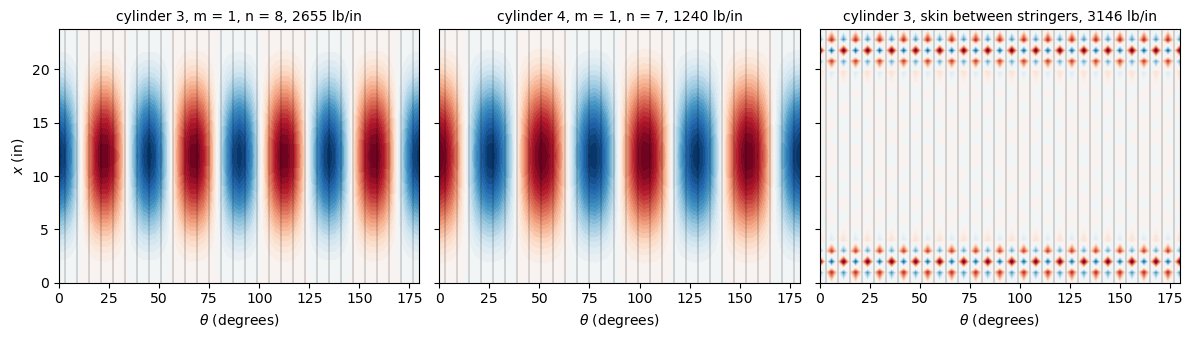

In [8]:
def plot_w(ax, model, mode, title):
    w = model.skin_field(mode, W)
    xx, tt = np.meshgrid(model.xlin, np.degrees(model.theta), indexing='ij')
    lim = np.abs(w).max()
    ax.contourf(tt, xx, w, levels=np.linspace(-lim, lim, 41), cmap='RdBu_r')
    for th in np.degrees(model.theta_stringer):
        ax.axvline(th, color='k', lw=0.2)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(r'$\theta$ (degrees)')


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, k in zip(axes[:2], [3, 4]):
    model, Ncr, mn, modes = results[(k, 'test')]
    plot_w(ax, model, modes[:, 0], 'cylinder %d, m = %d, n = %d, %.0f lb/in'
           % (k, *mn[0], Ncr[0]))
model, Ncr, mn, modes = results[(3, 'test')]
local = [i for i, (m, n) in enumerate(mn) if n >= 25]
if local:
    i = local[0]
    plot_w(axes[2], model, modes[:, i],
           'cylinder 3, skin between stringers, %.0f lb/in' % Ncr[i])
axes[0].set_ylabel('$x$ (in)')
plt.tight_layout()
plt.show()

## Discussion

**Discrete and smeared stringers.** With the membrane pre-buckling state of
the theory, the discrete model is within 0.2 % of $\bar{N}_c$ and 2.1 % of
$\bar{N}_s$ for cylinder 3, and within 0.6 % of both for cylinder 4. The
ratio of the clamped critical loads of the external and internal
stringers, 2.12, is that of the theory. The stringers are closely spaced,
about 7 to 9 stringers per circumferential wave of the modes, and the
discrete model, with the bending, extension and torsion of the stringers
given by the plate elements, behaves as the smeared theory for these
cylinders. The lowest modes have $n = 8$ and $n = 7$ circumferential
waves, one more than the numbers of waves into which the cylinders buckled
in the tests, $n_e$ of Table I; the modes with $n_e$ waves are 8 % and
21 % above the lowest ones, see the list above.

**Pre-buckling state.** The linear pre-buckling state of the clamped
cylinders, with the radial displacement restrained at the ends, gives
critical loads 2.1 % and 1.1 % above those of the membrane state, in line
with the conclusion of [1] that a membrane pre-buckled shape is sufficient
for the assessment of the eccentricity effects. The lowest mode of the skin
between the stringers, near the ends, where the pre-buckling state departs
from the membrane state, is above the lowest mode of the whole cylinder
(the value of the figure, with the mesh used, is not converged). This
agrees with the strain gages of [1], which indicated no local buckling
before general buckling.

**Tests.** The experimental loads are 80 % and 78 % of the linear
pre-buckling loads of the model, close to their ratios to the clamped
theory, 82 % and 79 %; for all their cylinders, [1] gives the experimental
loads as 70 to 95 % of the clamped theory. The model is that of a perfect
cylinder: [1] names the neglect of initial imperfections, besides the
boundary conditions and the pre-buckling solution of the theory, as a
contribution to the difference between theory and experiment. The externally stiffened cylinders buckled with a loud report
and diamond-shaped buckles of large amplitude [1]. The model also leaves
out the two butt joints of each cylinder, with doubler plates and rivets,
the actual restraint of the potted ends and the fillets of the stiffeners,
and assumes a linear elastic material, whereas the stress-strain curves of
[1] are linear up to at least 85 % of the maximum stress.
The model is not adjusted to the tests.

## Reference

[1] Card, M. F., and Jones, R. M., *Experimental and theoretical results
for buckling of eccentrically stiffened cylinders*, NASA TN D-3639, 1966,
[NTRS 19660027866](https://ntrs.nasa.gov/citations/19660027866).